# DL_03 — Floor prediction (single-task DL)

**Purpose.** Predict `FLOOR` (5 global classes; floor 4 exists only in building 2).

**Model.** The shared-trunk MLP from `src/signal2space_dl/model.py` with only the **floor** head
enabled (`experiment="floor_only"`). It is a single-task ablation: comparing it with the multitask model in
DL_05 shows whether sharing a trunk across tasks helps or hurts this target.

**Selection.** Fixed a-priori hyperparameters (`TrainConfig`), early stopping on the
internal-validation loss. The held-out partition is scored only after the checkpoint is frozen; the
evaluation step re-checks the checkpoint SHA-256 recorded at training time.

**Outputs.** `models/dl_03_floor_model.pt|json`, `data/tables/dl_03_floor_*`, `data/figures/dl_03_floor_*`.

In [1]:
import sys
from pathlib import Path

# Locate the repository root whether Jupyter starts in the root or in "Deep Learning Pipeline/".
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "signal2space_dl").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import json, platform
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from signal2space_dl import config as C, data as D, evaluate as E, plots as P
from signal2space_dl.cli import run_compare, run_evaluate, run_train

paths = C.Paths(ROOT).ensure()
cfg = C.TrainConfig()
pd.set_option("display.width", 160, "display.max_columns", 30)
print(f"Repository: {ROOT}")
print(f"Python {platform.python_version()} | torch {torch.__version__} | pandas {pd.__version__} | NumPy {np.__version__}")

Repository: /home/user/Signal2Space
Python 3.13.18 | torch 2.15.0+cu132 | pandas 3.0.6 | NumPy 2.5.4


In [2]:
data = D.prepare(paths, coord_scale=cfg.coord_scale, save=False)
print({s: len(f) for s, f in data.frames.items()})

{'internal_train': 16085, 'internal_validation': 3852, 'heldout_validation': 1111}


## 1. Train (or reuse the frozen checkpoint)

In [3]:
CHECKPOINT = paths.models / "dl_03_floor_model.pt"
RETRAIN = False   # set True to retrain from scratch; the default reuses the committed checkpoint
if RETRAIN or not CHECKPOINT.exists():
    run_train(data, paths, cfg, ["floor_only"])
meta = json.loads((paths.models / "dl_03_floor_model.json").read_text())
print(json.dumps({k: meta[k] for k in ["tasks", "selected_epoch", "epochs_run", "best_internal_validation_loss",
                                       "n_parameters", "training_seconds", "device", "torch_version"]}, indent=1))

{
 "tasks": [
  "floor"
 ],
 "selected_epoch": 43,
 "epochs_run": 58,
 "best_internal_validation_loss": 0.07456731886785721,
 "n_parameters": 699397,
 "training_seconds": 55.9,
 "device": "cpu",
 "torch_version": "2.15.0+cu132"
}


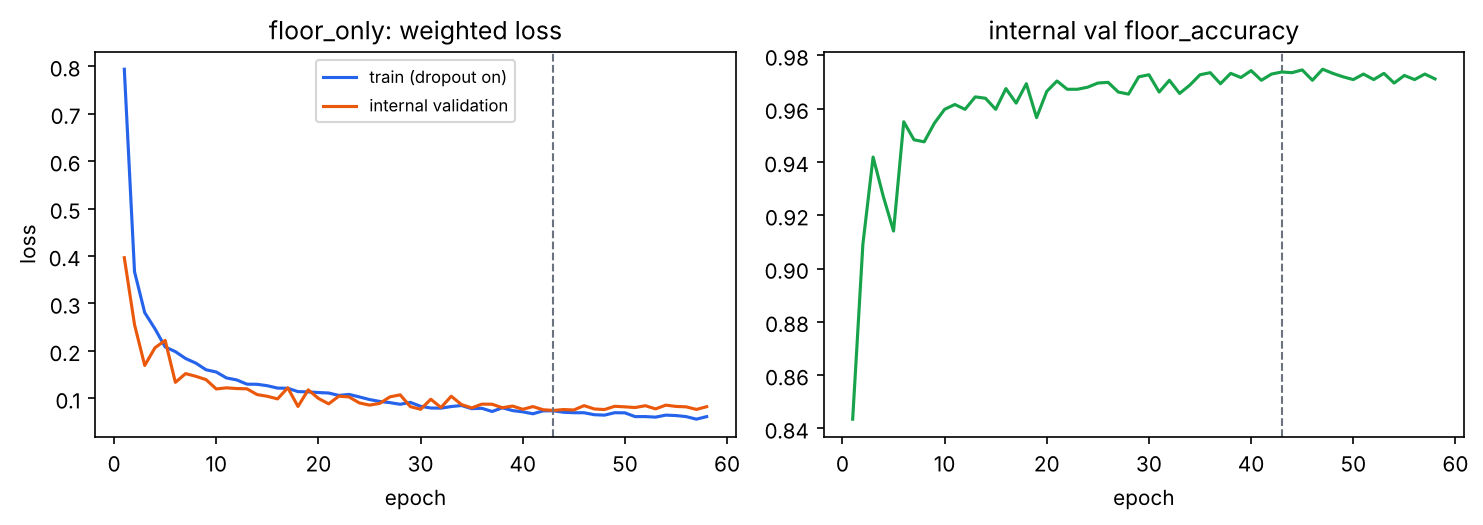

In [4]:
history = pd.read_csv(paths.tables / "dl_03_floor_training_history.csv")
P.training_curves(history, paths, "dl_03_floor", "floor_only")
display(Image(paths.figures / "dl_03_floor_training_curves.png"))

## 2. Evaluate the frozen model (internal validation, then held-out)

In [5]:
preds, rows = run_evaluate(data, paths, ["floor_only"])
metrics = pd.DataFrame(rows).drop(columns=["checkpoint_sha256"])
display(metrics.round(4))

,model,experiment,split,task,n_rows,selected_epoch,accuracy,macro_f1,balanced_accuracy,n_correct
0,DL floor_only,floor_only,internal_validation,floor,3852,43,0.9738,0.9750,0.9743,3751
1,DL floor_only,floor_only,heldout_validation,floor,1111,43,0.8992,0.8843,0.8783,999


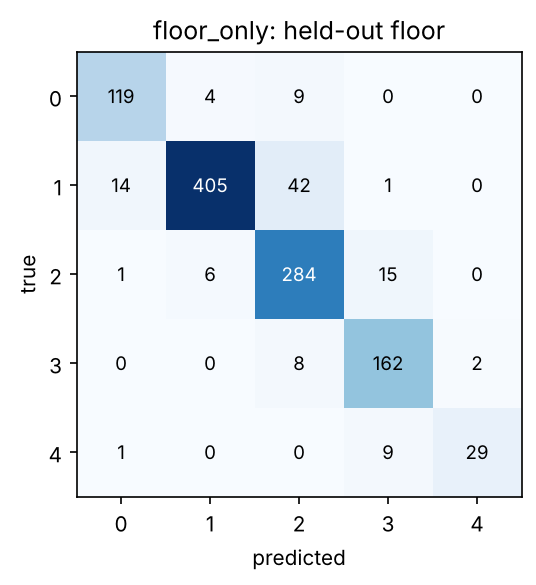

,model,task,class,support,precision,recall,f1
0,DL floor_only,floor,0,132,0.8815,0.9015,0.8914
1,DL floor_only,floor,1,462,0.9759,0.8766,0.9236
2,DL floor_only,floor,2,306,0.8280,0.9281,0.8752
3,DL floor_only,floor,3,172,0.8663,0.9419,0.9025
4,DL floor_only,floor,4,39,0.9355,0.7436,0.8286


In [6]:
display(Image(paths.figures / "dl_03_floor_heldout_confusion_matrix.png"))
display(pd.read_csv(paths.tables / "dl_03_floor_heldout_per_class.csv").round(4))

## 3. Same-partition comparison with the AML baseline

In [7]:
aml = pd.DataFrame(E.aml_metric_rows(paths))
cmp = pd.concat([aml[aml.task == "floor"], metrics[metrics.task == "floor"]], ignore_index=True)
cols = [c for c in ["model", "split", "accuracy", "macro_f1", "balanced_accuracy", "mae_longitude", "mae_latitude",
                    "mean_euclidean_error", "median_euclidean_error", "p90_euclidean_error"] if c in cmp]
display(cmp[cols].round(4))

,model,split,accuracy,macro_f1,balanced_accuracy,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error,p90_euclidean_error
0,AML Random Forest,internal_validation,0.9642,0.9678,0.9673,NaN,NaN,NaN,NaN,NaN
1,AML Random Forest,heldout_validation,0.8893,0.8727,0.8631,NaN,NaN,NaN,NaN,NaN
2,DL floor_only,internal_validation,0.9738,0.9750,0.9743,NaN,NaN,NaN,NaN,NaN
3,DL floor_only,heldout_validation,0.8992,0.8843,0.8783,NaN,NaN,NaN,NaN,NaN


## Findings

- The frozen floor-only model, selected at epoch 43 of 58, gets **89.92%** held-out accuracy and 88.43% macro F1. The AML Random Forest gets 88.93% and 87.27%.
- The paired bootstrap 95% interval for DL minus AML accuracy is [-0.36, +2.43] percentage points, so this split does not establish an improvement.
- Accuracy drops sharply from internal validation (97.38%) to held-out. Both model families show this, which points to distribution shift in `validationData.csv` (other users and phones, collected later).
- Floor 4 has the lowest held-out recall (74.4%, 39 rows). Floor 1 recall is 87.7%, and many of its rows are predicted as floor 2.